<center><h1>Ngo_Jesse_HW7</h1></center>

Name: Jesse Ngo
<br>
Github Username: hjngo
<br>
USC ID: 4722249405

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [2]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, balanced_accuracy_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as imb_make_pipeline

warnings.filterwarnings("ignore", category=FutureWarning)
RS = 552   # random state
dataPath = Path("..") / "data"
assert dataPath.exists(), f"Run the notebook from its own folder (cwd is {Path.cwd()})"

### (a) Download the Anuran Calls (MFCCs) Data Set

In [6]:
LABELS = ["Family", "Genus", "Species"]
frogs = pd.read_csv(dataPath / "Frogs_MFCCs.csv")
X = frogs.filter(like="MFCCs")          # 22 MFCC features (RecordID is not a feature)
Y = frogs[LABELS]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.7,
                                                    random_state=RS)

### (b) Train a classifier for each label

#### (i) Research

For $n$ instances with true label set $Y_i$ and predicted set $Z_i$ (here each set holds $L = 3$ labels: family, genus, species):
- **Exact match ratio** $= \frac{1}{n}\sum_i I(Z_i = Y_i)$: share of instances with **all** labels correct (strictest).
- **Hamming loss** $= \frac{1}{nL}\sum_i \sum_{j} I(z_{ij} \ne y_{ij})$: share of individual labels that are wrong.
- **Hamming score** $= \frac{1}{n}\sum_i \frac{|Y_i \cap Z_i|}{|Y_i \cup Z_i|}$ (Sorower): per-instance overlap of true and predicted labels.

#### (ii) Train a SVM for each of the labels

In [10]:
# Multi-label metrics from (i); Y and Z are n x 3 arrays of labels
def multilabel_scores(Y, Z):
    match = (np.asarray(Y) == np.asarray(Z)).sum(axis=1)        # correct labels per row
    L = Y.shape[1]
    return {"exact match": np.mean(match == L),
            "Hamming score": np.mean(match / (2 * L - match)),   # |Y∩Z| / |Y∪Z|
            "Hamming loss": np.mean((L - match) / L)}

# Binary relevance: one classifier per label, each tuned by 10-fold CV, then all three
# label predictions on the test set are scored together
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RS)
# Prints chosen parameters + test balanced accuracy (mean recall over classes) per label
def fit_per_label(model, grid):
    preds, rows = {}, {}
    for lab in LABELS:
        gs = GridSearchCV(model, grid, cv=cv10, n_jobs=-1).fit(X_train, Y_train[lab])
        preds[lab] = gs.predict(X_test)
        rows[lab] = {**gs.best_params_,
                     "balanced acc": balanced_accuracy_score(Y_test[lab], preds[lab])}
    print(pd.DataFrame(rows).T.round(4).to_string())
    scores = multilabel_scores(Y_test, pd.DataFrame(preds)[LABELS])
    print("test:", {k: round(float(v), 4) for k, v in scores.items()})
    return scores

# Gaussian kernel exp(-||x - x'||^2 / (2 sigma^2)), so gamma = 1 / (2 sigma^2).
sigmas = np.arange(0.3, 1.81, 0.3)
grid_rbf = {"estimator__C": np.logspace(-1, 4, 6),
            "estimator__gamma": 1 / (2 * sigmas ** 2)}
res = {"Gaussian SVM": fit_per_label(OneVsRestClassifier(SVC(kernel="rbf")), grid_rbf)}

         estimator__C  estimator__gamma  balanced acc
Family           10.0            1.3889        0.9704
Genus          1000.0            1.3889        0.9583
Species          10.0            1.3889        0.9692
test: {'exact match': 0.9843, 'Hamming score': 0.9877, 'Hamming loss': 0.0108}


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [19]:
# L1 penalty with a linear kernel; LinearSVC is one-vs-rest by default
l1_svm = make_pipeline(StandardScaler(),
                       LinearSVC(penalty="l1", dual=False, max_iter=50000))
# C capped at 100: accuracy is flat for C >= 1, and larger C barely regularizes, so
# liblinear struggles to converge (esp. on SMOTE data)
grid_l1 = {"linearsvc__C": np.logspace(-3, 2, 11)}
res["L1 SVM"] = fit_per_label(l1_svm, grid_l1)

         linearsvc__C  balanced acc
Family         1.0000        0.6928
Genus          3.1623        0.8314
Species        1.0000        0.8881
test: {'exact match': 0.9176, 'Hamming score': 0.939, 'Hamming loss': 0.0526}


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [20]:
# SMOTE inside the pipeline: applied only to the training part of each CV fold
l1_smote = imb_make_pipeline(StandardScaler(), SMOTE(random_state=RS),
                             LinearSVC(penalty="l1", dual=False, max_iter=50000))
res["L1 SVM + SMOTE"] = fit_per_label(l1_smote, grid_l1)
pd.DataFrame(res).T.round(4)

         linearsvc__C  balanced acc
Family        31.6228        0.9199
Genus          1.0000        0.8912
Species        0.1000        0.9035
test: {'exact match': 0.8624, 'Hamming score': 0.9078, 'Hamming loss': 0.0747}


,exact match,Hamming score,Hamming loss
Gaussian SVM,0.9843,0.9877,0.0108
L1 SVM,0.9176,0.9390,0.0526
L1 SVM + SMOTE,0.8624,0.9078,0.0747


**Conclusions:** The Gaussian-kernel SVM is the best on all three metrics, so the classes are not linearly separable in the MFCC space; the linear L1 SVM is worse on every metric. SMOTE lowers exact match and Hamming score, which are dominated by the large classes, but raises the balanced accuracy of each label (most for Family and Genus): it recovers rare classes at a small cost on the common ones.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

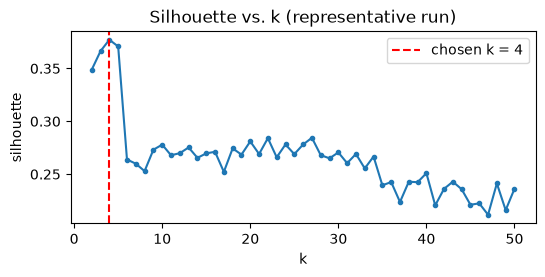

In [7]:
# k in {2, ..., 50} chosen by the largest silhouette (undefined for k = 1), computed on
# a random 3,000-point sample per k since the full version is O(n^2) for n = 7,195.
X_all, Y_all = X.values, Y.values
def kmeans_best_k(seed):
    best, sil = (-1, None, None), []
    for k in range(2, 51):
        km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X_all)
        s = silhouette_score(X_all, km.labels_, sample_size=3000, random_state=seed)
        sil.append(s)
        if s > best[0]:
            best = (s, k, km.labels_)
    return best[1], best[2], sil

k0, clusters0, sil0 = kmeans_best_k(0)   # representative run (seed 0) for (a) and (b)
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(range(2, 51), sil0, marker=".")
ax.axvline(k0, color="red", ls="--", label=f"chosen k = {k0}")
ax.set_xlabel("k"); ax.set_ylabel("silhouette"); ax.legend()
ax.set_title("Silhouette vs. k (representative run)")
plt.show()

### (b) Determine which family is the majority

In [8]:
# Majority (family, genus, species) of each cluster, read from the true labels
def majority_labels(clusters):
    df = pd.DataFrame(Y_all, columns=LABELS).assign(cluster=clusters)
    return df.groupby("cluster")[LABELS].agg(lambda s: s.mode()[0])

majority_labels(clusters0)   # representative run

,Family,Genus,Species
cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae
2,Dendrobatidae,Ameerega,Ameeregatrivittata
3,Hylidae,Hypsiboas,HypsiboasCinerascens


Majorities are taken independently for each label, so a cluster's triplet may not be a real (family, genus, species) combination, which is an expected limitation of this approach.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [11]:
# Monte Carlo: 50 runs of (a)-(c) with different seeds. Hamming distance = number of the
# 3 labels where the cluster's majority triplet differs from the true triplet.
runs = []
for seed in range(50):
    k, clusters, _ = kmeans_best_k(seed)
    Z = majority_labels(clusters).loc[clusters].values   # point -> cluster's triplet
    s = multilabel_scores(Y_all, Z)
    runs.append({"k": k, "Hamming distance": 3 * s["Hamming loss"],
                 "Hamming score": s["Hamming score"],
                 "Hamming loss": s["Hamming loss"]})
runs = pd.DataFrame(runs)
print("representative run:", runs.iloc[0].drop("k").round(4).to_dict())
print("chosen k (count over 50 runs):", runs["k"].value_counts().to_dict())
runs.drop(columns="k").agg(["mean", "std"]).round(4)

representative run: {'Hamming distance': 0.6673, 'Hamming score': 0.7703, 'Hamming loss': 0.2224}
chosen k (count over 50 runs): {4: 50}


,Hamming distance,Hamming score,Hamming loss
mean,0.6719,0.7677,0.2240
std,0.0170,0.0094,0.0057


## 3. ISLR 12.6.2

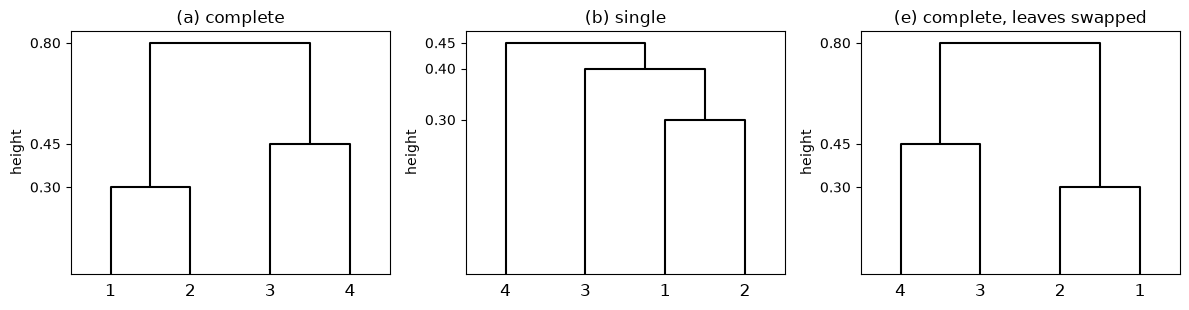

In [9]:
D = squareform(np.array([[0, .3, .4, .7], [.3, 0, .5, .8],
                         [.4, .5, 0, .45], [.7, .8, .45, 0]]))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
Zc, Zs = linkage(D, method="complete"), linkage(D, method="single")
Zswap = Zc.copy()
Zswap[:, [0, 1]] = Zc[:, [1, 0]]   # swap the two sides of every fusion
for ax, Zl, title in [(axes[0], Zc, "(a) complete"), (axes[1], Zs, "(b) single"),
                      (axes[2], Zswap, "(e) complete, leaves swapped")]:
    dendrogram(Zl, labels=[1, 2, 3, 4], ax=ax, color_threshold=0,
               above_threshold_color="k")
    ax.set_yticks(Zl[:, 2]); ax.set_title(title); ax.set_ylabel("height")
plt.tight_layout(); plt.show()

**(a)** Complete linkage: {1, 2} fuse at 0.3, {3, 4} at 0.45, then {1, 2} and {3, 4} at 0.8.

**(b)** Single linkage: {1, 2} fuse at 0.3, then 3 joins at 0.4, then 4 joins at 0.45.

**(c)** {1, 2} and {3, 4}.

**(d)** {1, 2, 3} and {4}.

**(e)** Third dendrogram: the sides of each fusion are swapped (leaves 4, 3, 2, 1), but the fusions and heights are the same as in (a).